In [78]:
# Data manipulation and numerical libraries
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration and warning management
import warnings
%matplotlib inline
warnings.filterwarnings('ignore')  # Suppress warnings for clean output

In [79]:
# Load Netflix dataset from CSV and preview the first 5 rows
df = pd.read_csv(r'D:\VS code\data\netflix_titles.csv')

# Display the first 5 rows
df.head(5)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [80]:
# Return the number of rows and columns in the dataset
df.shape

(8807, 12)

In [81]:
# Return the list of column names in the dataframe
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='str')

In [82]:
# Check the data type of each column in the dataframe
df.dtypes

show_id           str
type              str
title             str
director          str
cast              str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
description       str
dtype: object

In [83]:
# Display concise summary of dataframe
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 3.9 MB


In [84]:
# Count the number of missing values in each column
df.isna().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [85]:
# Count duplicate rows based on the 'show_id' column
df.duplicated(subset='show_id').sum()

np.int64(0)

In [86]:
# Calculate the percentage of missing values for each column and round to 3 decimal places
(df.isna().mean() * 100).round(3)

show_id          0.000
type             0.000
title            0.000
director        29.908
cast             9.368
country          9.436
date_added       0.114
release_year     0.000
rating           0.045
duration         0.034
listed_in        0.000
description      0.000
dtype: float64

In [87]:
# Convert 'date_added' to datetime format, coercing parsing errors to NaT
df['date_added'] = pd.to_datetime(df['date_added'], format='%B %d, %Y', errors='coerce')

# Drop rows where 'date_added' is missing or could not be parsed
df.dropna(subset=['date_added'], inplace=True)

In [88]:
# Replace missing values in text columns with a placeholder
df['description'] = df['description'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')
df['director'] = df['director'].fillna('Unknown')

In [89]:
# Fill missing values in the 'country' column with the most frequent (mode) country
df['country'] = df['country'].fillna(df['country'].mode()[0])

In [90]:
# Fill missing values in the 'rating' column with the most frequent (mode) rating
df['rating'].fillna(df['rating'].mode()[0], inplace=True)

0       PG-13
1       TV-MA
2       TV-MA
3       TV-MA
4       TV-MA
        ...  
8802        R
8803    TV-Y7
8804        R
8805       PG
8806    TV-14
Name: rating, Length: 8709, dtype: str

In [91]:
# Fill missing 'duration' values using the most frequent value (mode) grouped by content type ('Movie' or 'TV Show')
df['duration'] = (
    df.groupby('type')['duration']
      .transform(lambda x: x.fillna(x.mode()[0]))
)

In [92]:
# Verify that all missing values across the dataframe have been successfully handled
df.isna().sum()

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          4
duration        0
listed_in       0
description     0
dtype: int64

In [93]:
# Split "90 min" -> 90 and "min", "2 Seasons" -> 2 and "Seasons"
df[['duration_num', 'duration_unit']] = df['duration'].str.split(' ', n=1, expand=True)

In [94]:
# Convert the 'duration_num' column to numeric values, coercing any parsing errors to NaN
df['duration_num'] = pd.to_numeric(df['duration_num'], errors='coerce')

In [95]:
# Extract and split duration values into separate columns based on content type
df['movie_minutes'] = df.loc[df['type'] == 'Movie', 'duration_num']
df['tv_seasons'] = df.loc[df['type'] == 'TV Show', 'duration_num']

In [96]:
# Check the number of missing values across all columns after cleaning
df.isna().sum()

show_id             0
type                0
title               0
director            0
cast                0
country             0
date_added          0
release_year        0
rating              4
duration            0
listed_in           0
description         0
duration_num        0
duration_unit       0
movie_minutes    2578
tv_seasons       6131
dtype: int64

In [97]:
df.info()

<class 'pandas.DataFrame'>
Index: 8709 entries, 0 to 8806
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   show_id        8709 non-null   str           
 1   type           8709 non-null   str           
 2   title          8709 non-null   str           
 3   director       8709 non-null   str           
 4   cast           8709 non-null   str           
 5   country        8709 non-null   str           
 6   date_added     8709 non-null   datetime64[us]
 7   release_year   8709 non-null   int64         
 8   rating         8705 non-null   str           
 9   duration       8709 non-null   str           
 10  listed_in      8709 non-null   str           
 11  description    8709 non-null   str           
 12  duration_num   8709 non-null   int64         
 13  duration_unit  8709 non-null   str           
 14  movie_minutes  6131 non-null   float64       
 15  tv_seasons     2578 non-null   float6

## Basic descriptive analysis
Movies vs TV Shows: what share of the catalogue is each? (type)

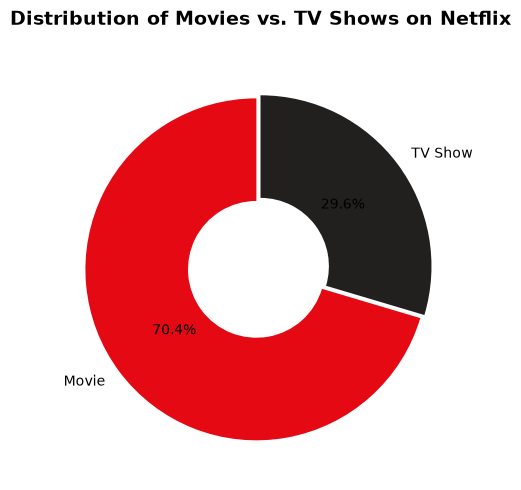

In [98]:
# Count the occurrences of each content type ('Movie' vs 'TV Show')
type_counts = df['type'].value_counts()

# Create a pie chart showing the proportion of Movies versus TV Shows
plt.figure(figsize=(5, 5))
colors = ['#E50914', '#221F1F']
explode = (0.03, 0)

plt.pie(type_counts, labels=type_counts.index, autopct='%1.1f%%',
        startangle=90, colors=colors,  explode=explode, wedgeprops={'width': 0.6})

plt.title('Distribution of Movies vs. TV Shows on Netflix', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

Content by release_year: when was most of the content made?

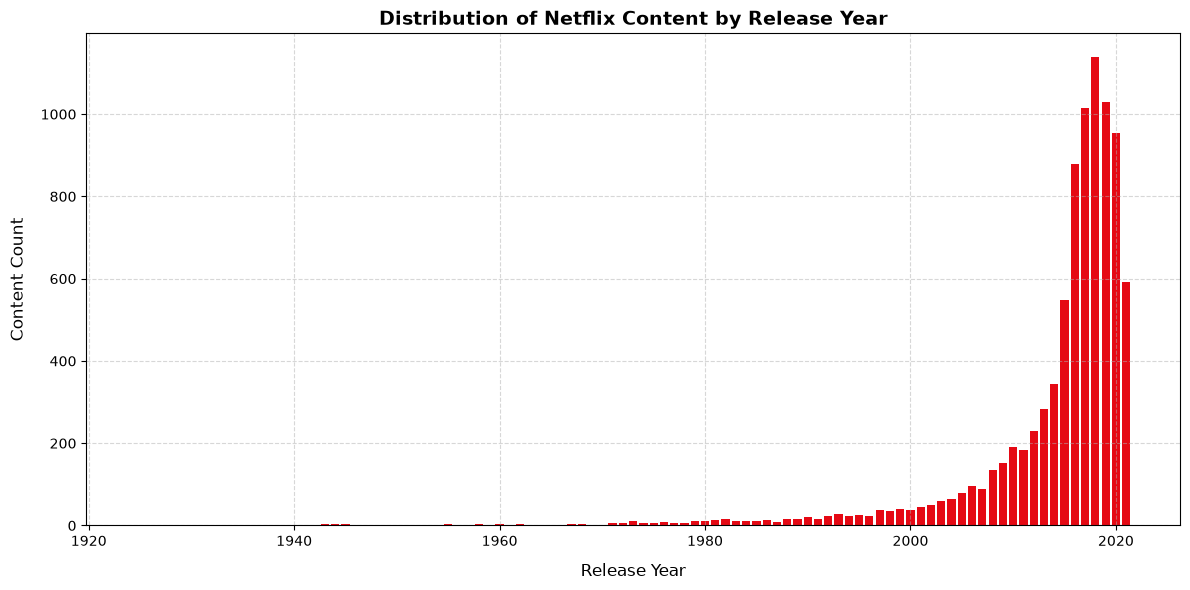

In [99]:
# Calculate title counts by release year
yearly_counts = df['release_year'].value_counts().sort_index()

# Create a professional line plot showing content release trends
plt.figure(figsize=(12, 6))
plt.bar(yearly_counts.index, yearly_counts.values, color='#E50914')

plt.title('Distribution of Netflix Content by Release Year', fontsize=14, fontweight='bold')
plt.xlabel('Release Year', fontsize=12, labelpad=10)
plt.ylabel('Content Count', fontsize=12, labelpad=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [100]:
# Fix the few rows where the movie length landed in the rating column
df = df[~df['rating'].astype(str).str.contains('min')].copy()

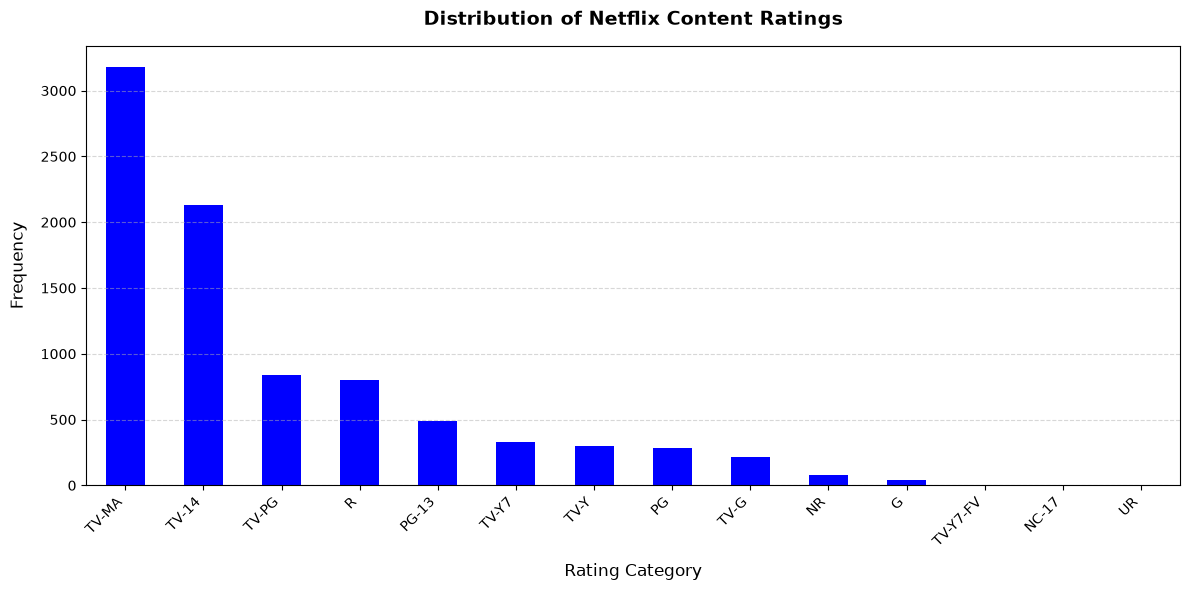

In [101]:
# Calculate and sort rating counts in descending order for clear comparison
rating_counts = df['rating'].value_counts()

# Create a professional bar plot for content ratings
plt.figure(figsize=(12, 6))
rating_counts.plot(kind='bar', color='blue', width=0.5)

plt.title('Distribution of Netflix Content Ratings', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Rating Category', fontsize=12, labelpad=10)
plt.ylabel('Frequency', fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [102]:
def explode_col(df, col):
    s = df[col].apply(
        lambda v: v if isinstance(v, list)
        else ([] if pd.isna(v) else str(v).split(','))
    )
    out = s.explode().dropna().astype(str)
    out = (out.str.replace(r"[\[\]'\"]", '', regex=True)   # remove brackets and quotes
              # .str.replace('\xa0', ' ', regex=False)    # Handling non-breaking spaces (\xa0)
              .str.replace(r'\s+', ' ', regex=True)
              .str.strip()
              .str.lower())                                # fixes the case differences
    return out[(out != '') & (out != 'unknown')]

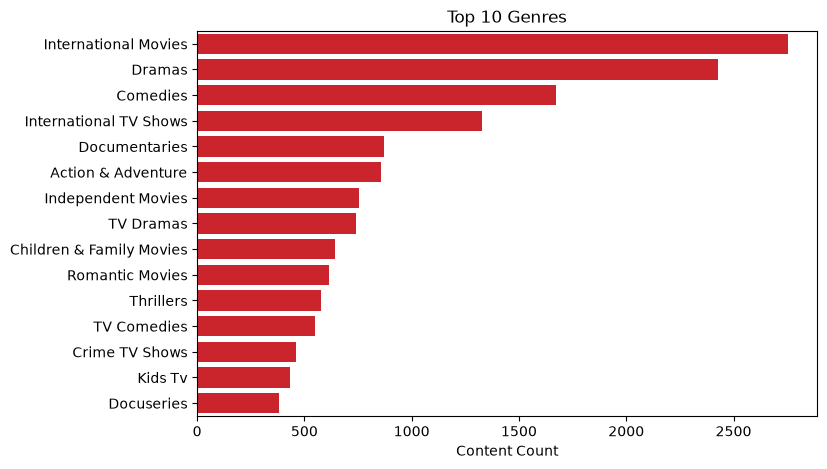

In [103]:
#Top 10 genres

genres = explode_col(df, 'listed_in').value_counts().head(15)
labels = [g.title().replace('Tv ', 'TV ') for g in genres.index]

plt.figure(figsize=(8, 5))
sns.barplot(x=genres.values, y=labels, color='#e50914')
plt.title('Top 10 Genres')
plt.xlabel('Content Count')
plt.show()

5. Top 10 countries

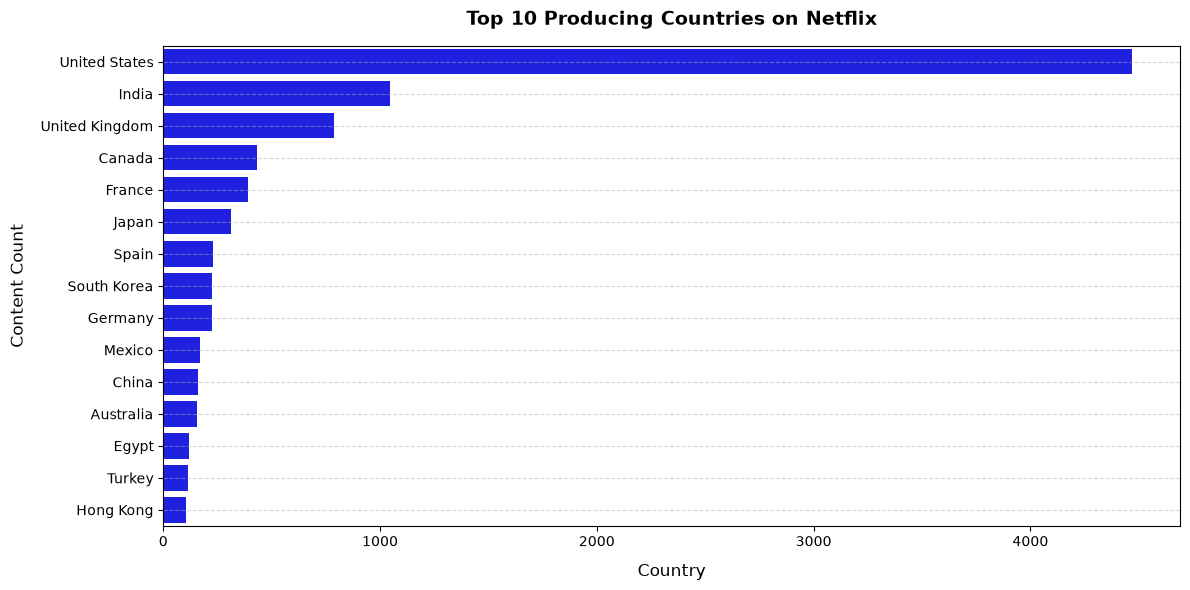

In [104]:
countries = explode_col(df, 'country').value_counts().head(15)
labels = [g.title() for g in countries.index]

plt.figure(figsize=(12, 6))
sns.barplot(x=countries.values, y=labels, color='blue')
plt.title('Top 10 Producing Countries on Netflix', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Country', fontsize=12, labelpad=10)
plt.ylabel('Content Count', fontsize=12, labelpad=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

6. Most frequent directors and actors

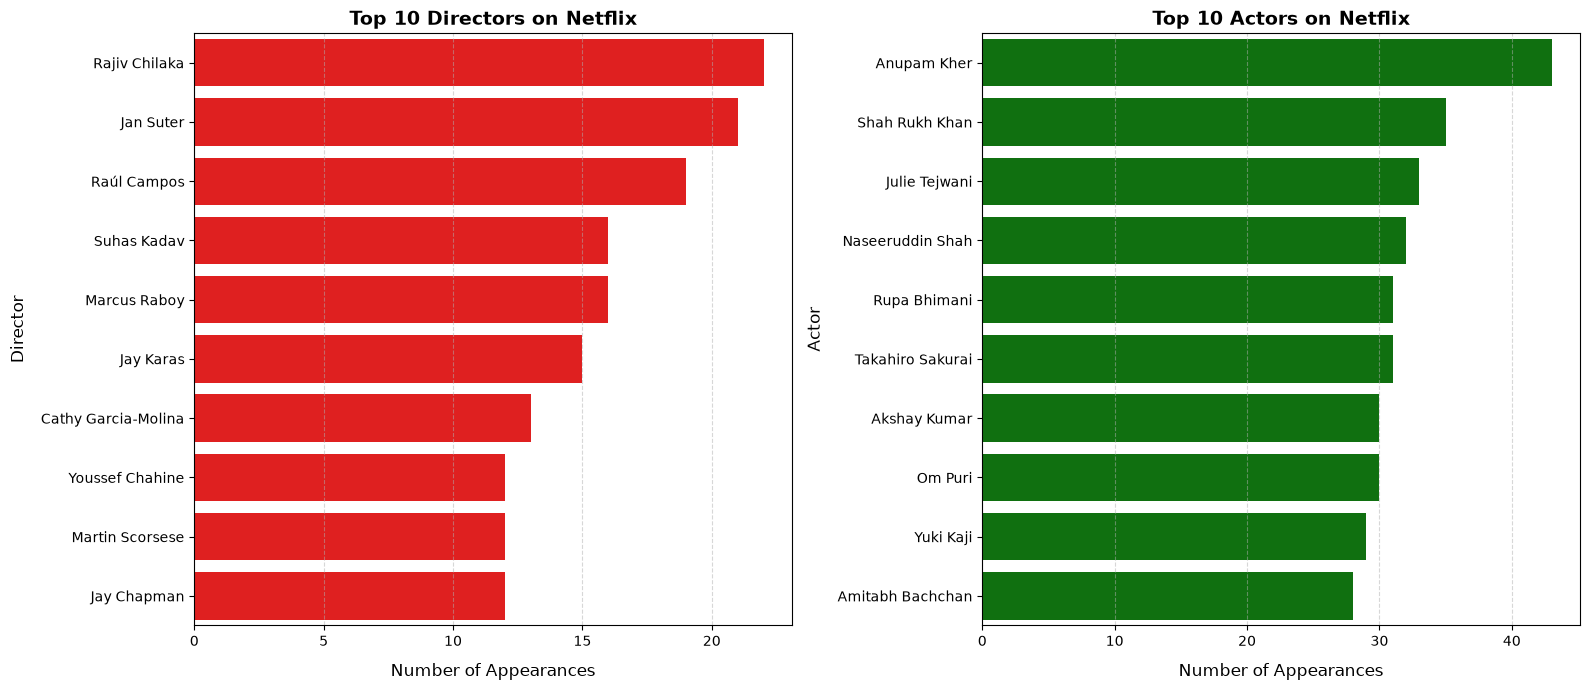

In [105]:
# Extract top 10 directors and cast members using explode_col
directors = explode_col(df, 'director').value_counts().head(10)
labels_dir = [d.title() for d in directors.index]

actors = explode_col(df, 'cast').value_counts().head(10)
labels_act = [a.title() for a in actors.index]

# Create a professional side-by-side subplot visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Plot top directors
sns.barplot(x=directors.values, y=labels_dir, ax=axes[0], color='red')
axes[0].set_title('Top 10 Directors on Netflix', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Number of Appearances', fontsize=12, labelpad=10)
axes[0].set_ylabel('Director', fontsize=12, labelpad=10)
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

# Plot top actors
sns.barplot(x=actors.values, y=labels_act, ax=axes[1], color='green')
axes[1].set_title('Top 10 Actors on Netflix', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Number of Appearances', fontsize=12, labelpad=10)
axes[1].set_ylabel('Actor', fontsize=12, labelpad=10)
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Time-based analysis

- Titles added per year or month (date_added): when did the platform grow fastest?
- Gap between release_year and the year added: how much is new vs older content?
- Is the mix of movies vs TV shows changing over time?

In [106]:
df.dtypes

show_id                     str
type                        str
title                       str
director                    str
cast                        str
country                     str
date_added       datetime64[us]
release_year              int64
rating                      str
duration                    str
listed_in                   str
description                 str
duration_num              int64
duration_unit               str
movie_minutes           float64
tv_seasons              float64
dtype: object

In [107]:
# A few rows have no date, so drop them for time analysis only
df_time = df.copy()
df_time['year_added'] = df_time['date_added'].dt.year
df_time['month_added'] = df_time['date_added'].dt.month
df_time['month_name'] = df_time['date_added'].dt.month_name()

print(df_time[['date_added', 'year_added', 'month_added']].head(10))

  date_added  year_added  month_added
0 2021-09-25        2021            9
1 2021-09-24        2021            9
2 2021-09-24        2021            9
3 2021-09-24        2021            9
4 2021-09-24        2021            9
5 2021-09-24        2021            9
6 2021-09-24        2021            9
7 2021-09-24        2021            9
8 2021-09-24        2021            9
9 2021-09-24        2021            9


Titles added per year and per month

Per year (shows when growth was fastest):

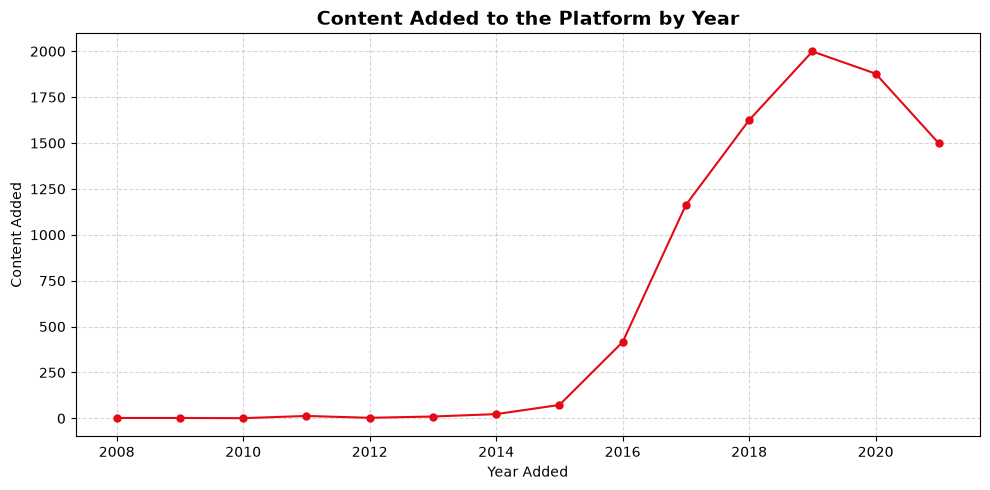

In [108]:
yearly = df_time['year_added'].value_counts().sort_index()

plt.figure(figsize=(10, 5))
yearly.plot(kind='line', marker='o', color='#e50914', markersize=5)
plt.title('Content Added to the Platform by Year', fontsize=14, fontweight='bold')
plt.xlabel('Year Added')
plt.ylabel('Content Added')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [109]:
# Year-over-year growth: the biggest jump is your "fastest growth" year
growth = yearly.pct_change() * 100
print(growth.round(1))
print("Fastest growth year:", growth.idxmax())

year_added
2008       NaN
2009       0.0
2010     -50.0
2011    1200.0
2012     -76.9
2013     233.3
2014     130.0
2015     217.4
2016     469.9
2017     179.6
2018      39.7
2019      23.0
2020      -6.1
2021     -20.2
Name: count, dtype: float64
Fastest growth year: 2011


Per month (shows seasonality):

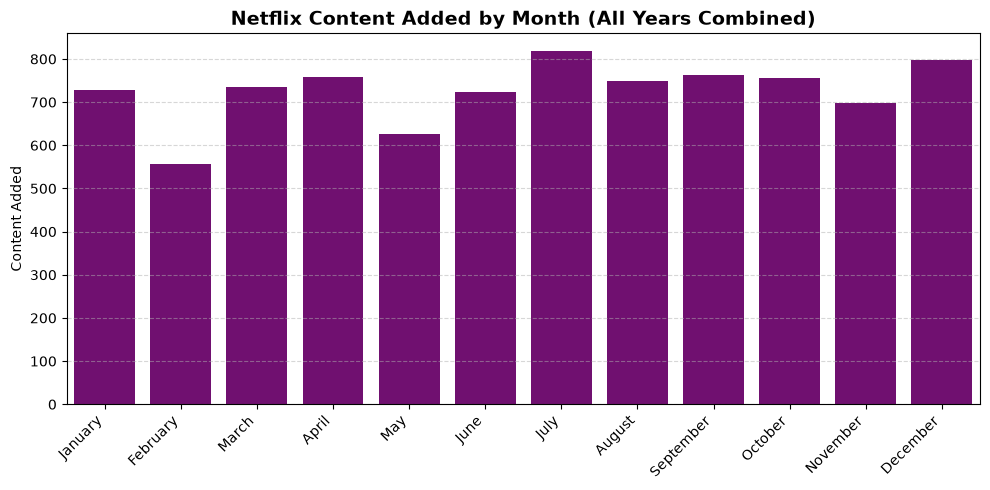

In [110]:
# Ensure months are ordered correctly and calculate counts
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
monthly = df_time['month_name'].value_counts().reindex(month_order)

# Create a bar plot for monthly content additions
plt.figure(figsize=(10, 5))
sns.barplot(x=monthly.index, y=monthly.values, color='purple')

plt.title('Netflix Content Added by Month (All Years Combined)', fontsize=14, fontweight='bold')
plt.xlabel('')
plt.ylabel('Content Added')
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Year x month heatmap

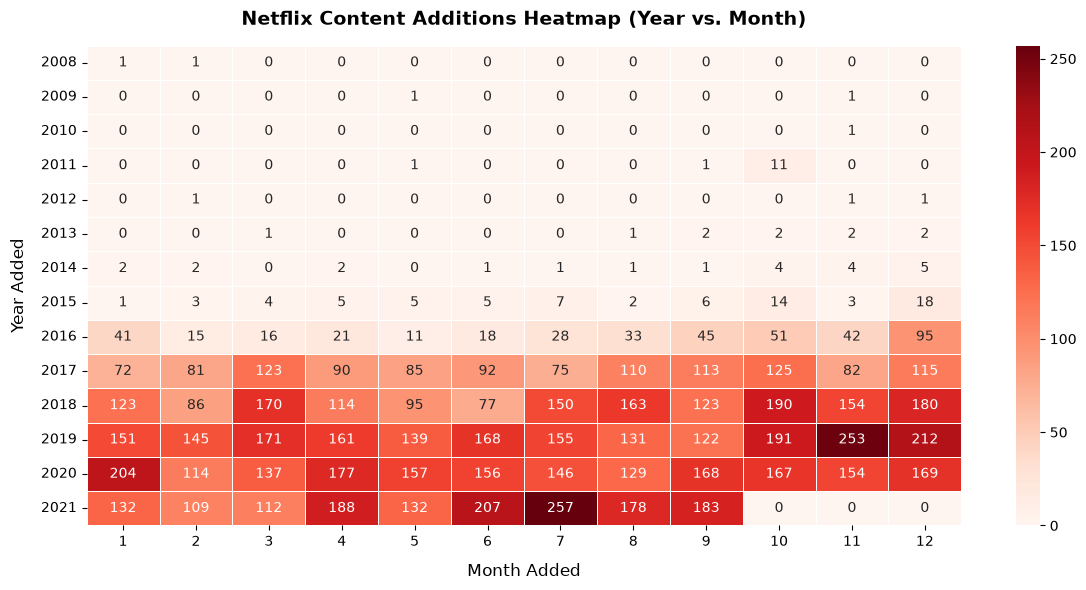

In [111]:
# Create a pivot table to aggregate content additions by year and month
heat = df_time.pivot_table(index='year_added', columns='month_added', values='show_id', aggfunc='count').fillna(0)

# Create a heatmap visualization
plt.figure(figsize=(12, 6))
sns.heatmap(heat, cmap='Reds', annot=True, fmt='.0f', linewidths=0.5)

plt.title('Netflix Content Additions Heatmap (Year vs. Month)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Month Added', fontsize=12, labelpad=10)
plt.ylabel('Year Added', fontsize=12, labelpad=10)
plt.tight_layout()
plt.show()

2. Gap between release year and year added

In [112]:
# Check the data types for 'year_added' and 'release_year' columns
df_time[['year_added', 'release_year']].dtypes

year_added      int32
release_year    int64
dtype: object

Note: Since release_year is already stored as a 4-digit integer, passing it through `pd.to_datetime()` can cause unexpected date-parsing behavior. It is safer to use `pd.to_numeric()` to ensure clean calculations.

In [113]:
# Convert release_year to numeric and calculate the time lag (gap) in years
df_time['release_year'] = pd.to_numeric(df_time['release_year'], errors='coerce')
df_time['gap_years'] = (df_time['year_added'] - df_time['release_year']).astype(int)
df_time['gap_years'].describe()

count    8706.000000
mean        4.691707
std         8.793479
min        -3.000000
25%         0.000000
50%         1.000000
75%         5.000000
max        93.000000
Name: gap_years, dtype: float64

In [114]:
df_time.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,duration_num,duration_unit,movie_minutes,tv_seasons,year_added,month_added,month_name,gap_years
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",90,min,90.0,NaN,2021,9,September,1
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2,Seasons,NaN,2.0,2021,9,September,0
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",United States,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,1,Season,NaN,1.0,2021,9,September,0
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,United States,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",1,Season,NaN,1.0,2021,9,September,0
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2,Seasons,NaN,2.0,2021,9,September,0


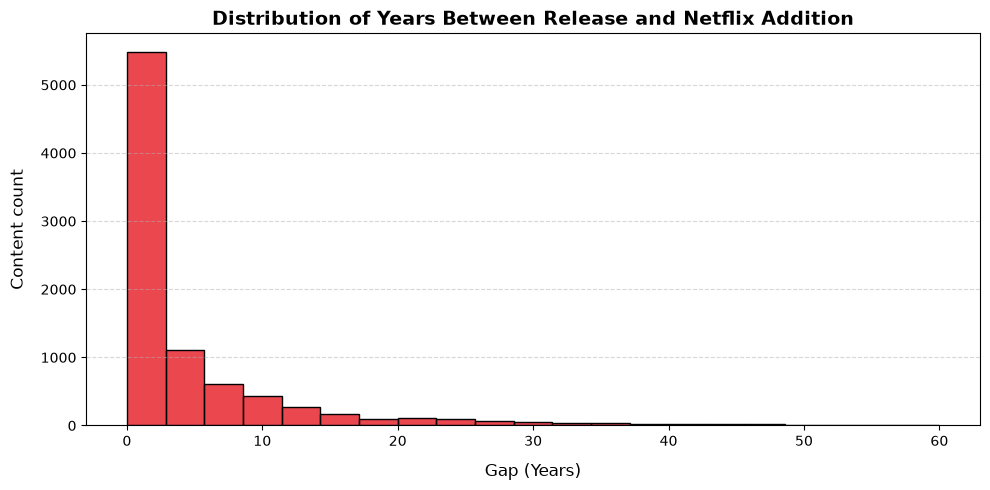

In [115]:
# Distribution of the gap (zoomed in to 0-100 years so outliers don't squash it)
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_time[df_time['gap_years'].between(0, 60)],
    x='gap_years',
    bins=21,
    color='#e50914'
)

plt.title('Distribution of Years Between Release and Netflix Addition', fontsize=14, fontweight='bold')
plt.xlabel('Gap (Years)', fontsize=12, labelpad=10)
plt.ylabel('Content count', fontsize=12, labelpad=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Now bucket it into “new vs older” content, which is easier to explain:

In [116]:
def bucket(gap):
    if gap <= 1:
        return 'New (0-1 yr)'
    elif gap <= 5:
        return 'Recent (2-5 yrs)'
    elif gap <= 10:
        return 'Older (6-10 yrs)'
    else:
        return 'Catalogue (10+ yrs)'

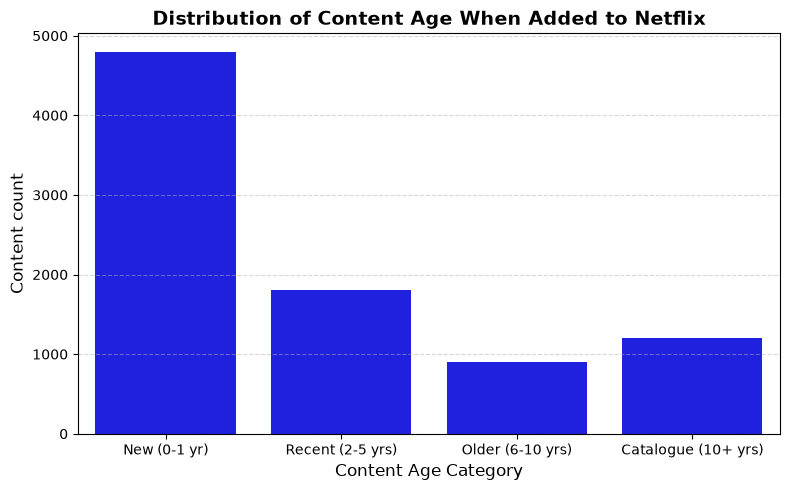

In [117]:
df_time['content_age'] = df_time['gap_years'].apply(bucket)

age_counts = df_time['content_age'].value_counts()
order = ['New (0-1 yr)', 'Recent (2-5 yrs)', 'Older (6-10 yrs)', 'Catalogue (10+ yrs)']

plt.figure(figsize=(8, 5))
sns.barplot(x=age_counts.reindex(order).index,
            y=age_counts.reindex(order).values, color='blue')
plt.title('Distribution of Content Age When Added to Netflix', fontsize=14, fontweight='bold')
plt.xlabel('Content Age Category', fontsize=12)
plt.ylabel('Content count', fontsize=12)
plt.xticks(rotation=0, fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [118]:
df_time['content_age'].value_counts()

content_age
New (0-1 yr)           4793
Recent (2-5 yrs)       1809
Catalogue (10+ yrs)    1198
Older (6-10 yrs)        906
Name: count, dtype: int64

In [119]:
print((age_counts / age_counts.sum() * 100).round(1))

content_age
New (0-1 yr)           55.1
Recent (2-5 yrs)       20.8
Catalogue (10+ yrs)    13.8
Older (6-10 yrs)       10.4
Name: count, dtype: float64


3. Is the Movies vs TV Shows mix changing?

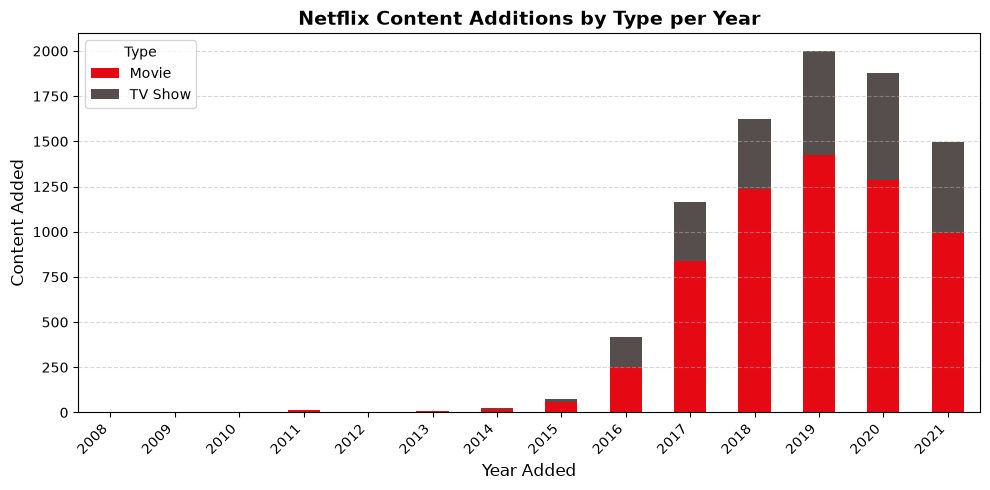

In [120]:
mix = pd.crosstab(df_time['year_added'], df_time['type'])

# Absolute counts per year
mix.plot(kind='bar', stacked=True, figsize=(10, 5), color=['#e50914', '#564d4d'])

plt.title('Netflix Content Additions by Type per Year', fontsize=14, fontweight='bold')
plt.xlabel('Year Added', fontsize=12)
plt.ylabel('Content Added', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.legend(title='Type', frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

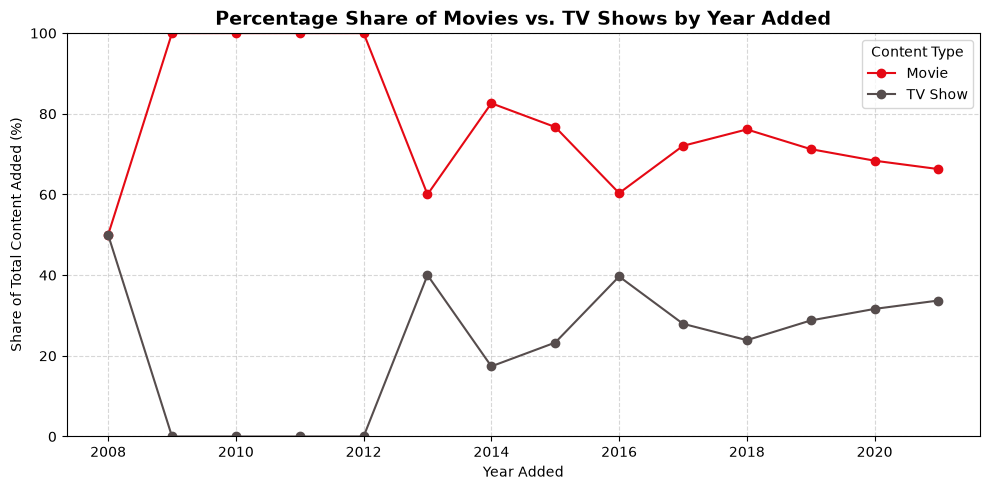

In [121]:
# Share (%) per year: this shows whether the *mix* is changing
mix_pct = mix.div(mix.sum(axis=1), axis=0) * 100

mix_pct.plot(kind='line', marker='o', figsize=(10, 5), color=['#e50914', '#564d4d'])

plt.title('Percentage Share of Movies vs. TV Shows by Year Added', fontsize=14, fontweight='bold')
plt.xlabel('Year Added')
plt.ylabel('Share of Total Content Added (%)')
plt.ylim(0, 100)
plt.legend(title='Content Type', frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [122]:
print(mix_pct.round(1))

type        Movie  TV Show
year_added                
2008         50.0     50.0
2009        100.0      0.0
2010        100.0      0.0
2011        100.0      0.0
2012        100.0      0.0
2013         60.0     40.0
2014         82.6     17.4
2015         76.7     23.3
2016         60.3     39.7
2017         72.1     27.9
2018         76.1     23.9
2019         71.2     28.8
2020         68.4     31.6
2021         66.3     33.7


## Comparisons across columns
- Genre by country (e.g., what does India produce more of vs the US?)
- Rating by type (are TV shows more mature than movies?)
- Average movie length by year or genre (from duration)
- Number of seasons for TV shows by genre

In [123]:
# Split the dataset into Movies and TV Shows
movies = df[df['type'] == 'Movie'].copy()
tv = df[df['type'] == 'TV Show'].copy()

1. Genre by country

This needs both country and listed_in exploded, so each title is counted once for every country-genre pair it belongs to. That’s what you want here, but only use this DataFrame for this comparison.

In [124]:

def explode_col(df, col):

    temp = df.copy()

    # Convert values into lists
    def convert_to_list(v):
        if isinstance(v, list):
            return v
        elif pd.isna(v):
            return []
        else:
            return str(v).split(',')

    temp[col] = temp[col].apply(convert_to_list)

    # Explode column
    temp = temp.explode(col, ignore_index=True)

    # Clean the exploded values
    temp[col] = (
        temp[col]
        .dropna()
        .astype(str)
        .str.replace(r"[\[\]'\"]", '', regex=True)  # Removing brackets and quotation marks
        # .str.replace('\xa0', ' ', regex=False)  # Handling non-breaking spaces (\xa0)
        .str.replace(r'\s+', ' ', regex=True)
        .str.strip()  #  Removing extra whitespace.
        .str.lower()  # Converting text to lowercase.
    )

# Step 4: Remove missing, empty and unknown values
    temp = temp[
        temp[col].notna() &
        (temp[col] != '') &
        (temp[col] != 'unknown')
    ].copy()

    return temp.reset_index(drop=True)



In [125]:
# 1. Explode the 'country' column
cg = explode_col(df, 'country')
print("After country explosion:", cg.shape)
print(cg[['show_id', 'country']].head())

# 2. Explode the 'listed_in' (genre) column on the resulting DataFrame
cg = explode_col(cg, 'listed_in')
print("After genre explosion:", cg.shape)
print(cg[['show_id', 'country', 'listed_in']].head())

After country explosion: (10729, 16)
  show_id        country
0      s1  united states
1      s2   south africa
2      s3  united states
3      s4  united states
4      s5          india
After genre explosion: (23518, 16)
  show_id        country               listed_in
0      s1  united states           documentaries
1      s2   south africa  international tv shows
2      s2   south africa               tv dramas
3      s2   south africa            tv mysteries
4      s3  united states          crime tv shows


In [ ]:
# Filter India and United States
compare = cg[ cg['country'].isin(['india', 'united states'])].copy()

In [ ]:
# Find top 10 genres among these two countries
top_genres = compare['listed_in'].value_counts().head(10).index

# Filter top genres
compare = compare[compare['listed_in'].isin(top_genres)]

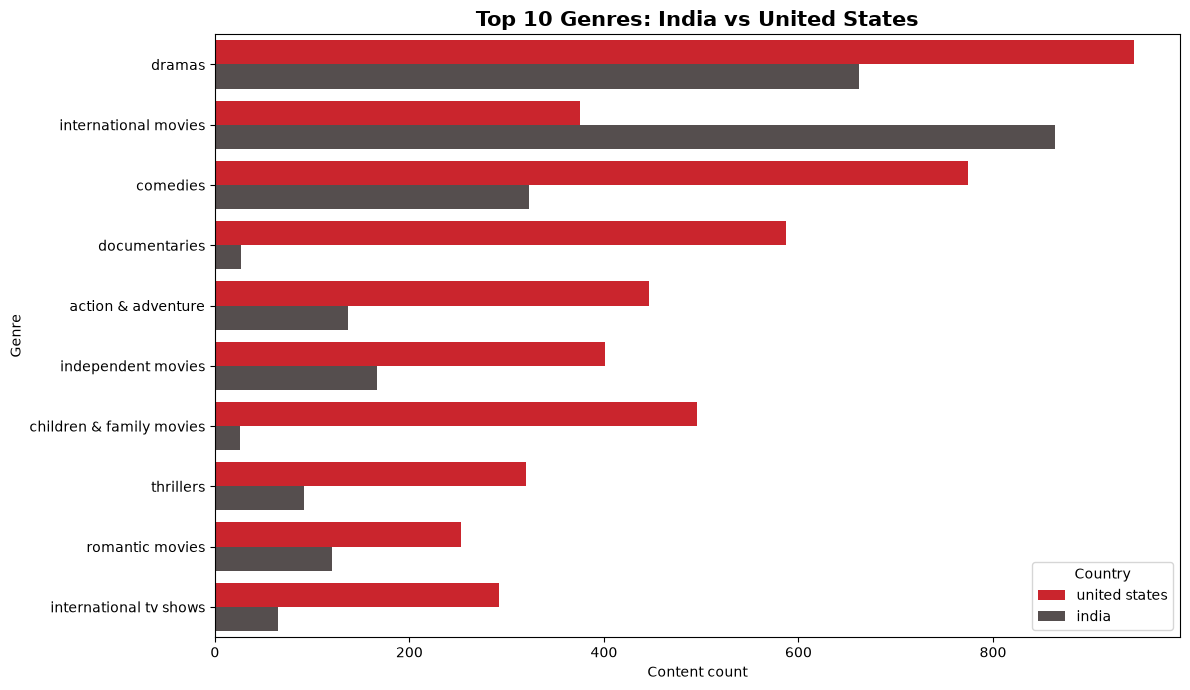

In [ ]:
# Visualization
plt.figure(figsize=(12, 7))

sns.countplot( data=compare, y='listed_in', hue='country', order=top_genres, palette=['#e50914', '#564d4d'])

plt.title('Top 10 Genres: India vs United States', fontsize=15, fontweight='bold')
plt.xlabel('Content count')
plt.ylabel('Genre')
plt.legend(title='Country')
plt.tight_layout()
plt.show()

Raw counts are misleading because the US has far more titles overall. Compare each country’s genre share instead:

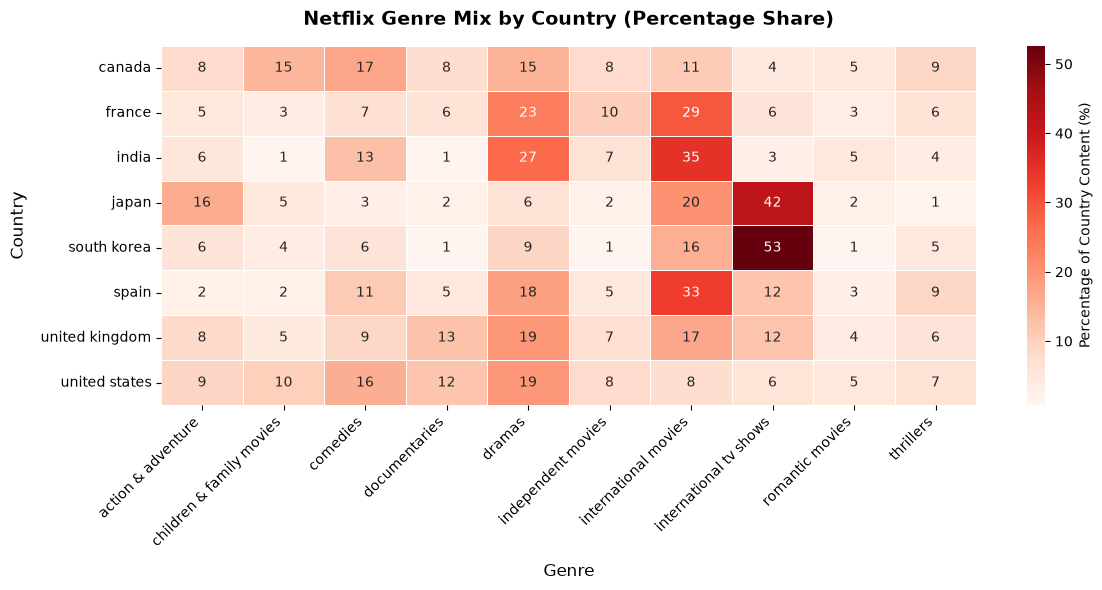

In [129]:
# Filter for top countries and top genres
top_countries = cg['country'].value_counts().head(8).index
sub = cg[cg['country'].isin(top_countries) & cg['listed_in'].isin(top_genres)]

# Calculate percentage share of each genre within each country
share = pd.crosstab(sub['country'], sub['listed_in'], normalize='index') * 100

# Create a heatmap visualization
plt.figure(figsize=(12, 6))
sns.heatmap(share, cmap='Reds', annot=True, fmt='.0f', linewidths=0.5, cbar_kws={'label': 'Percentage of Country Content (%)'})


plt.title('Netflix Genre Mix by Country (Percentage Share)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Genre', fontsize=12, labelpad=10)
plt.ylabel('Country', fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

Note the percentages are within the top-10 genres only, so rows won’t add to exactly 100.

## 2. Rating by type (are TV shows more mature?)

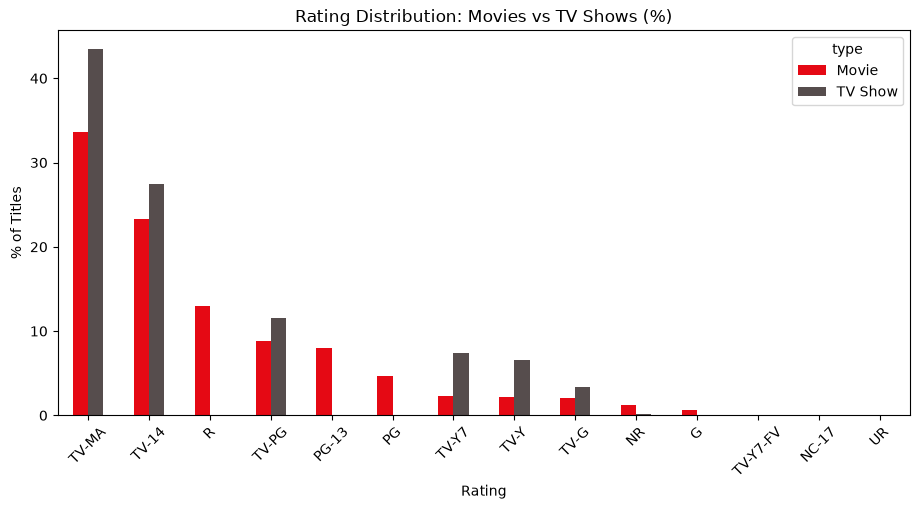

In [130]:
# Raw counts per rating
rating_type = pd.crosstab(df['rating'], df['type'])
rating_pct = rating_type.div(rating_type.sum(axis=0), axis=1) * 100   # % within each type

rating_pct.sort_values('Movie', ascending=False).plot(
    kind='bar', figsize=(11, 5), color=['#e50914', '#564d4d'])
plt.title('Rating Distribution: Movies vs TV Shows (%)')
plt.xlabel('Rating')
plt.ylabel('% of Titles')
plt.xticks(rotation=45)
plt.show()

Many separate ratings make the answer hard to see, so group them into audience levels:

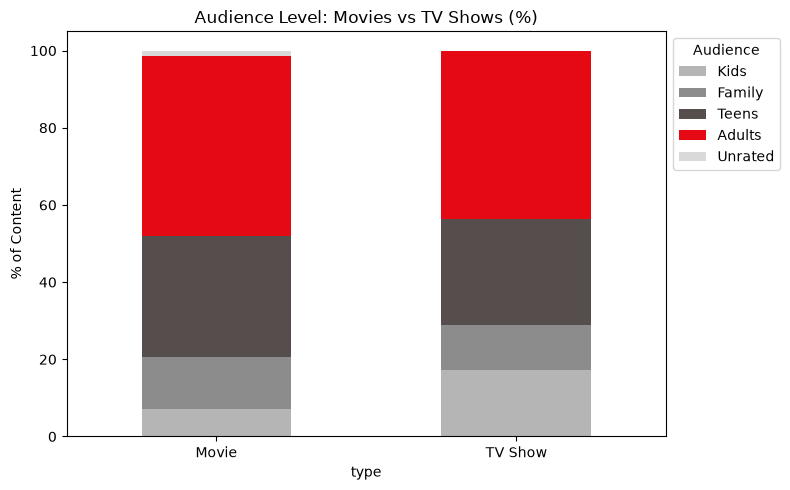

In [131]:
audience = {
    'TV-Y': 'Kids', 'TV-Y7': 'Kids', 'TV-Y7-FV': 'Kids', 'TV-G': 'Kids', 'G': 'Kids',
    'PG': 'Family', 'TV-PG': 'Family',
    'PG-13': 'Teens', 'TV-14': 'Teens',
    'R': 'Adults', 'TV-MA': 'Adults', 'NC-17': 'Adults',
    'NR': 'Unrated', 'UR': 'Unrated'
}
df['audience'] = df['rating'].map(audience)

aud = pd.crosstab(df['type'], df['audience'], normalize='index') * 100
aud = aud[['Kids', 'Family', 'Teens', 'Adults', 'Unrated']]

aud.plot(kind='bar', stacked=True, figsize=(8, 5),
         color=['#b5b5b5', '#8c8c8c', '#564d4d', '#e50914', '#d9d9d9'])
plt.title('Audience Level: Movies vs TV Shows (%)')
plt.ylabel('% of Content')
plt.xticks(rotation=0)
plt.legend(title='Audience', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

In [132]:
print(aud.round(1))

audience  Kids  Family  Teens  Adults  Unrated
type                                          
Movie      7.2    13.5   31.3    46.7      1.3
TV Show   17.3    11.6   27.4    43.6      0.1


Compare the “Adults” column between Movie and TV Show to answer your question directly.

#3. Average movie length by year or genre

By release year:

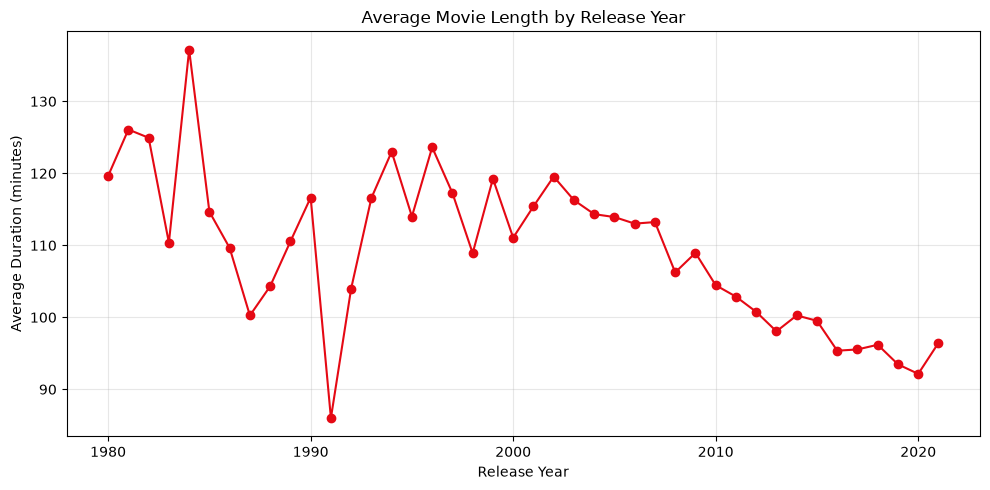

In [133]:
by_year = (
    movies[movies['release_year'] >= 1980]
    .groupby('release_year')['duration_num']
    .mean()
)

plt.figure(figsize=(10, 5))
by_year.plot(marker='o', color='#e50914')

plt.title('Average Movie Length by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Average Duration (minutes)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [134]:
print(movies['release_year'].dtype)

int64


By genre:

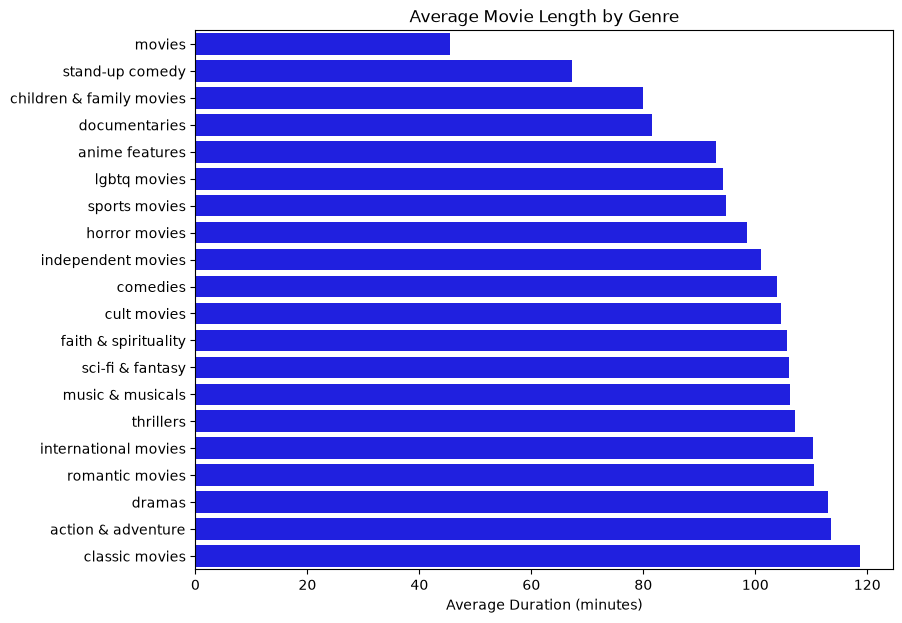

In [135]:
mg = explode_col(movies, 'listed_in')

# Only genres with enough titles to be meaningful
counts = mg['listed_in'].value_counts()
valid = counts[counts >= 30].index

by_genre = (mg[mg['listed_in'].isin(valid)]
            .groupby('listed_in')['duration_num'].mean()
            .sort_values())

plt.figure(figsize=(9, 7))
sns.barplot(x=by_genre.values, y=by_genre.index, color='blue')
plt.title('Average Movie Length by Genre')
plt.xlabel('Average Duration (minutes)')
plt.ylabel('')
plt.show()

A boxplot shows the spread, not just the average, which is more honest:

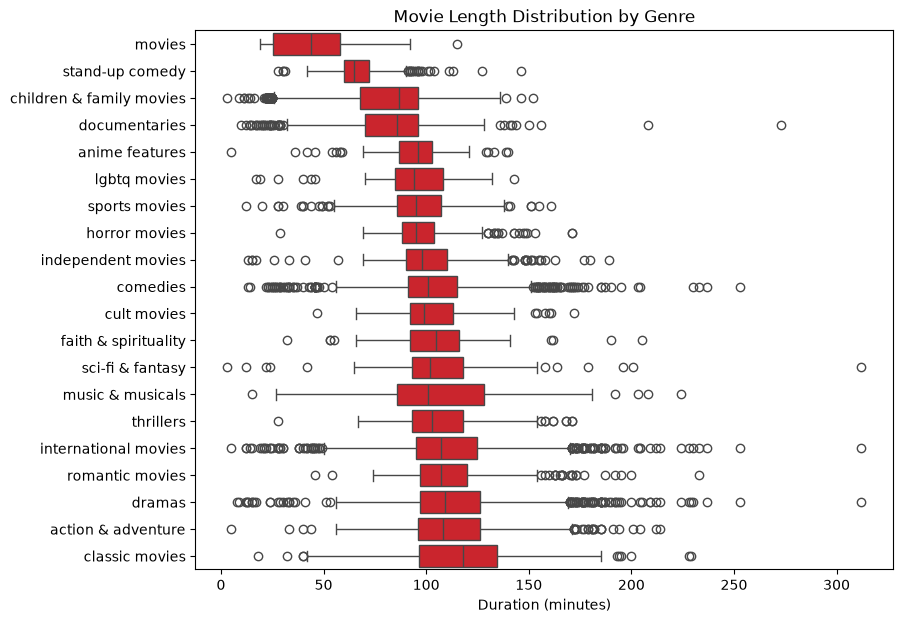

In [136]:
plt.figure(figsize=(9, 7))
sns.boxplot(data=mg[mg['listed_in'].isin(valid)], x='duration_num',
            y='listed_in', order=by_genre.index, color='#e50914')
plt.title('Movie Length Distribution by Genre')
plt.xlabel('Duration (minutes)')
plt.ylabel('')
plt.show()

4. Number of seasons by genre (TV shows)

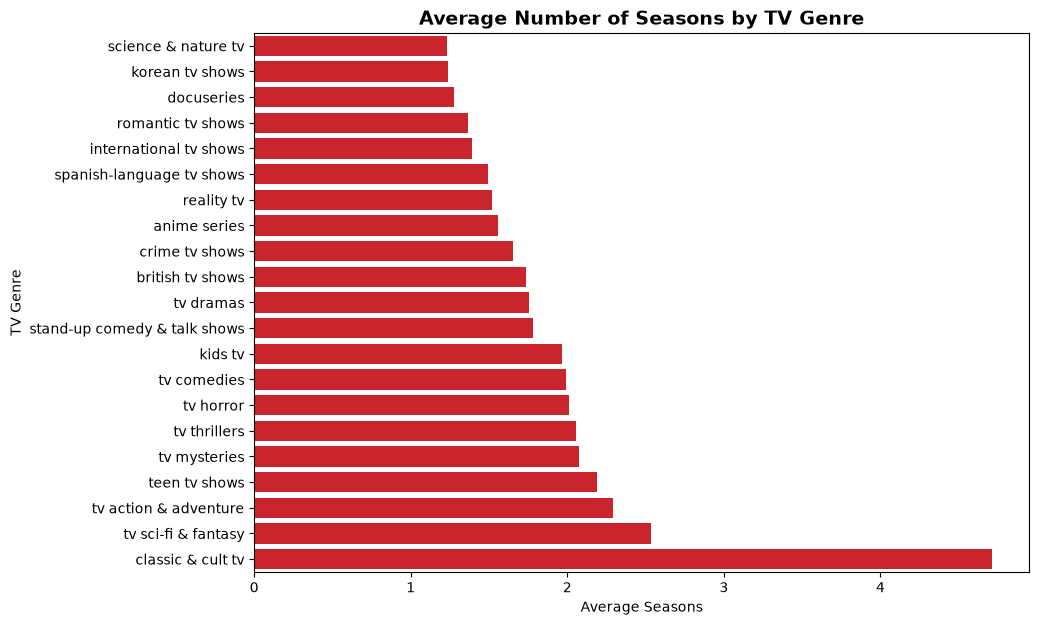

In [137]:
# Explode genres
tg = explode_col(tv, 'listed_in')

# Remove missing and empty genres
tg = tg.dropna(subset=['listed_in', 'duration_num'])

tg['listed_in'] = tg['listed_in'].str.strip()

tg = tg[tg['listed_in'] != '']

# Count TV shows per genre
counts = tg['listed_in'].value_counts()

# Keep genres containing at least 20 TV shows
valid = counts[counts >= 20].index

seasons = (tg[tg['listed_in'].isin(valid)]
           .groupby('listed_in')['duration_num'].mean()
           .sort_values())

plt.figure(figsize=(10, 7))
sns.barplot(x=seasons.values, y=seasons.index, color='#e50914')
plt.title('Average Number of Seasons by TV Genre',fontsize=14, fontweight='bold')
plt.xlabel('Average Seasons')
plt.ylabel('TV Genre')
plt.show()

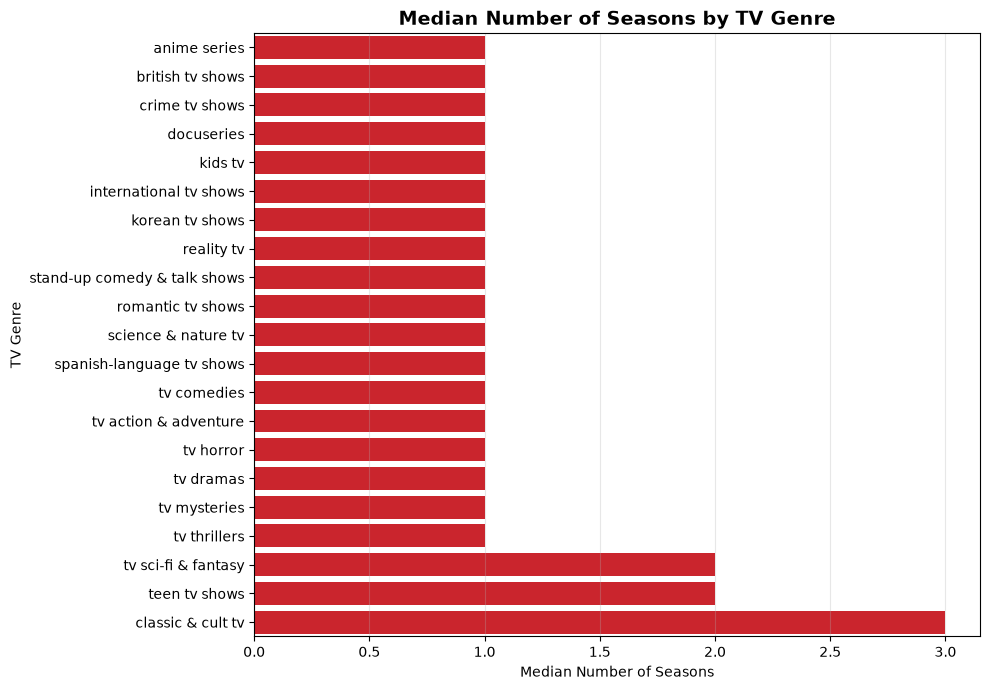

In [138]:
# Calculate median seasons per genre
seasons = (
    tg[tg['listed_in'].isin(valid)]
    .groupby('listed_in')['duration_num']
    .median()
    .sort_values(ascending=True)
)

# Visualization
plt.figure(figsize=(10, 7))

sns.barplot(x=seasons.values, y=seasons.index, color='#e50914')

plt.title('Median Number of Seasons by TV Genre', fontsize=14, fontweight='bold')
plt.xlabel('Median Number of Seasons')
plt.ylabel('TV Genre')

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [139]:
# Overall picture: most shows have just 1 season
print(tv['duration_num'].value_counts().sort_index().head(10))

duration_num
1     1791
2      384
3      178
4       89
5       55
6       30
7       18
8       13
9        8
10       5
Name: count, dtype: int64


The seasons data is heavily skewed, since most shows have only 1 season.

In [140]:
print((tv['duration_num'] == 1).mean() * 100)

69.47245927075252


# 5. Text analysis

- Title length analysis

### Title length analysis

       title_chars  title_words
count  8706.000000  8706.000000
mean     17.752699     3.115897
std      10.657417     1.866112
min       1.000000     1.000000
25%      10.000000     2.000000
50%      15.000000     3.000000
75%      23.000000     4.000000
max     104.000000    17.000000


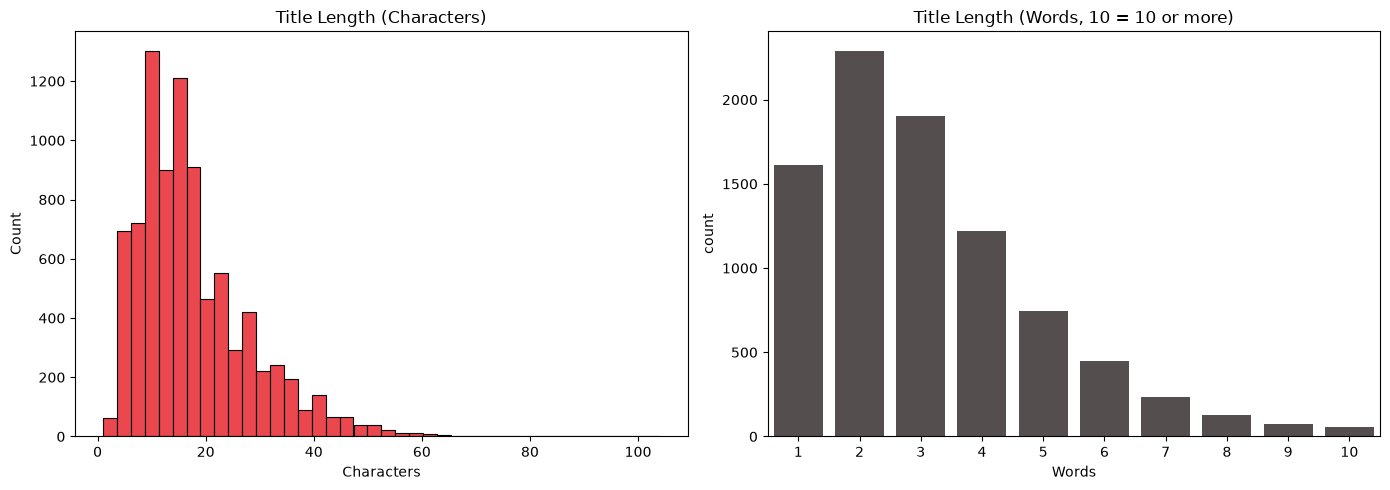

In [141]:
df['title_chars'] = df['title'].str.len()
df['title_words'] = df['title'].str.split().str.len()

print(df[['title_chars', 'title_words']].describe())

# Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['title_chars'], bins=40, color='#e50914', ax=axes[0])
axes[0].set_title('Title Length (Characters)')
axes[0].set_xlabel('Characters')

sns.countplot(x=df['title_words'].clip(upper=10), color='#564d4d', ax=axes[1])
axes[1].set_title('Title Length (Words, 10 = 10 or more)')
axes[1].set_xlabel('Words')

plt.tight_layout()
plt.show()

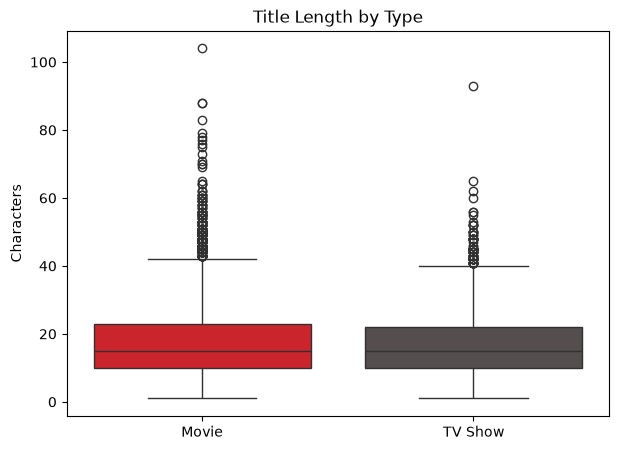

In [142]:
# Movies vs TV Shows:

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='type', y='title_chars', palette=['#e50914', '#564d4d'])
plt.title('Title Length by Type')
plt.xlabel('')
plt.ylabel('Characters')
plt.show()

In [143]:
print(df.groupby('type')['title_chars'].agg(['mean', 'median']).round(1))

         mean  median
type                 
Movie    18.0    15.0
TV Show  17.1    15.0


Has title length changed over time?

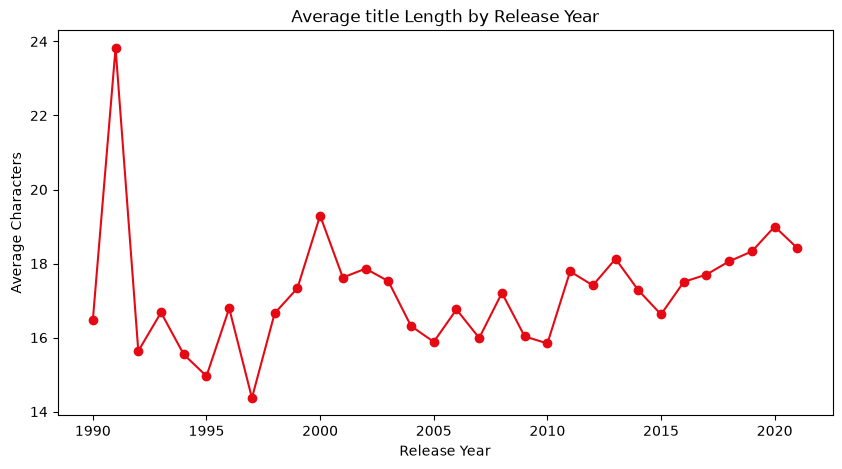

In [147]:
trend = (df[df['release_year'] >= 1990]
         .groupby('release_year')['title_chars'].mean())

plt.figure(figsize=(10, 5))
trend.plot(marker='o', color='#e50914')
plt.title('Average title Length by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Average Characters')
plt.show()

Longest and shortest titles:

In [145]:
print("Longest titles:")
print(df.nlargest(5, 'title_chars')[['title', 'title_chars']])

print("\nShortest titles:")
print(df.nsmallest(5, 'title_chars')[['title', 'title_chars']])

Longest titles:
                                                  title  title_chars
5164  Jim & Andy: The Great Beyond - Featuring a Ver...          104
2813  Ken Burns Presents: College Behind Bars: A Fil...           93
3240  Mike Birbiglia: What I Should Have Said Was No...           88
8462  The Power of Grayskull: The Definitive History...           88
4851  Steve Martin and Martin Short: An Evening You ...           83

Shortest titles:
     title  title_chars
2069     H            1
5958     9            1
7155     K            1
7687     P            1
2127    3%            2


In [176]:
# KPI
total = len(df)

year_added = df['date_added'].dt.year
gap = (year_added - df['release_year']).dropna()
yearly = year_added.value_counts().sort_index()

# one value per row for multi-value columns
genres = df['listed_in'].dropna().str.split(', ').explode().str.strip()
countries = df['country'].dropna().str.split(', ').explode().str.strip()

top_genre = genres.value_counts().index[0]
top_country = countries.value_counts().index[0]

# director-actor pairs
pairs['director'] = pairs['director'].str.split(', ')
pairs['cast'] = pairs['cast'].str.split(', ')
pairs = pairs.explode('director').explode('cast').drop_duplicates()
pair_counts = pairs.groupby(['director', 'cast'])['show_id'].nunique()

n_months = len(pd.period_range(df['date_added'].min(), df['date_added'].max(), freq='M'))

kpis = {
    'Total titles': total,
    'Total movies': len(movies),
    'Total TV shows': len(tv),
    'Movie share %': round(len(movies) / total * 100, 1),
    'TV share %': round(len(tv) / total * 100, 1),

    'Content added in latest year': int(yearly.iloc[-1]),
    'YoY growth % (latest vs previous)': round(yearly.pct_change().iloc[-1] * 100, 1),
    'Peak year': int(yearly.idxmax()),
    'Avg Content added per month': round(df['date_added'].notna().sum() / n_months, 1),
    'Busiest month': df['date_added'].dt.month_name().value_counts().idxmax(),

    'Avg content age when added (yrs)': round(gap.mean(), 1),
    '% new content (0-1 yr)': round((gap <= 1).mean() * 100, 1),
    '% catalogue content (10+ yrs)': round((gap > 10).mean() * 100, 1),

    '% adult-rated': round(df['rating'].dropna().isin(['TV-MA', 'R', 'NC-17']).mean() * 100, 1),
    '% kids': round(df['rating'].dropna().isin(['TV-Y', 'TV-Y7', 'TV-G', 'G']).mean() * 100, 1),
    'Top genre': top_genre,
    'Top genre share % of titles': round(df['listed_in'].str.contains(top_genre, na=False, regex=False).mean() * 100, 1),
    'Top country': top_country,
    'Top country share % of titles': round(df['country'].str.contains(top_country, na=False, regex=False).mean() * 100, 1),
    '% international content (non-US only)': round((df['country'].dropna().str.strip() != 'United States').mean() * 100, 1),

    'Avg movie length (min)': round(movies['duration_num'].mean(), 1),
    'Avg (median) seasons per TV show': tv['duration_num'].median(),
    '% TV shows with 1 season': round((tv['duration_num'] == 1).mean() * 100, 1),

    'Top-5 country concentration %': round(countries.value_counts().head(5).sum() / len(countries) * 100, 1),
    'Repeat-collaboration rate %': round((pair_counts >= 2).mean() * 100, 1)
}
print("Netflix Catalogue KPIs")
print(pd.Series(kpis, name='Value').to_frame().to_string())

Netflix Catalogue KPIs
                                                      Value
Total titles                                           8706
Total movies                                           6128
Total TV shows                                         2578
Movie share %                                          70.4
TV share %                                             29.6
Content added in latest year                           1498
YoY growth % (latest vs previous)                     -20.2
Peak year                                              2019
Avg Content added per month                            52.8
Busiest month                                          July
Avg content age when added (yrs)                        4.7
% new content (0-1 yr)                                 55.1
% catalogue content (10+ yrs)                          13.8
% adult-rated                                          45.8
% kids                                                 10.1
Top genre        

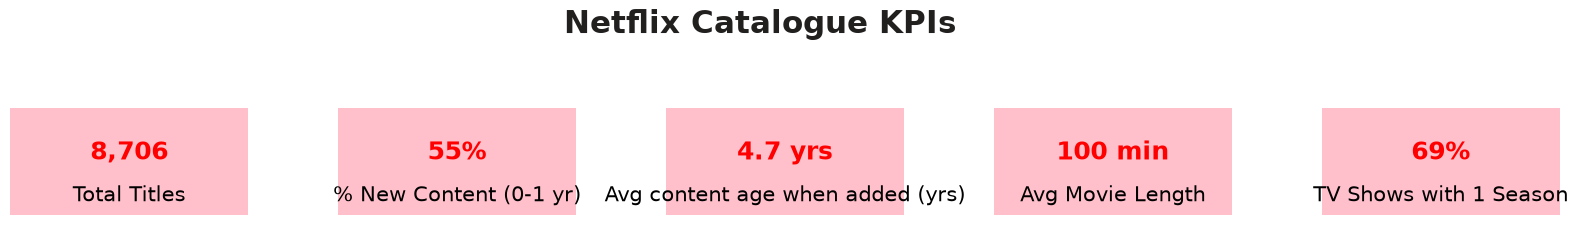

In [174]:
# ---------- Calculate KPIs ----------
movies = df[df['type'] == 'Movie']
tv = df[df['type'] == 'TV Show']

year_added = df['date_added'].dt.year
gap = (year_added - df['release_year']).dropna()
yearly = year_added.value_counts().sort_index()

cards = [
    ('Total Titles', f"{len(df):,}"),
    ('% New Content (0-1 yr)', f"{(gap <= 1).mean() * 100:.0f}%"),
    ('Avg content age when added (yrs)', f"{gap.mean():.1f} yrs"),
    ('Avg Movie Length', f"{movies['duration_num'].mean():.0f} min"),
    ('TV Shows with 1 Season', f"{(tv['duration_num'] == 1).mean() * 100:.0f}%"),
]


fig = plt.figure(figsize=(20, 11), facecolor='white')
fig.suptitle('Netflix Catalogue KPIs', fontsize=22, weight='bold', color=DARK, y=0.97)

# KPI cards
for i, (label, value) in enumerate(cards):
    ax = fig.add_subplot(gs[0, i * 2:(i + 1) * 2])
    ax.set_facecolor('pink')
    ax.text(0.5, 0.58, value, ha='center', va='center', fontsize=18, weight='bold', color='red')
    ax.text(0.5, 0.18, label, ha='center', va='center', fontsize=15, color='black')
    ax.set_xticks([]) 
    ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

plt.show()

# 📊 Netflix Exploratory Data Analysis (EDA) – Key Insight

###  1. **Content Composition (Movies vs. TV Shows)**

- **Movie Dominance**: Movies make up the majority of Netflix’s catalog at 70.4%, while TV Shows account for 29.6%.  

 `Portfolio Takeaway`: While Netflix started heavily focused on films, TV shows have become a crucial strategic driver for user retention, despite lower raw counts.
 
### 2. **Content Release & Platform Growth Trends**

- **Explosive Growth Era (2015–2019)**: Content production and platform additions scaled exponentially starting around 2015, peaking sharply around **2018–2019** before experiencing a slight downward adjustment in later years.   
- **Recent vs. Classic Content Gap**: The vast majority of content are added to Netflix within 0 to 3 years of their original release year. However, a long-tail distribution shows that older classic catalog content is also regularly acquired.   
- **Monthly Additions Seasonality**: Content additions are distributed fairly evenly throughout the year, with slight bumps during mid-year (July) and year-end (December).   

### 3. **Geographic Distribution & Demographics**

- **Top Producing Countries**: The United States leads content production by a massive margin, followed by India and the United Kingdom. Other major contributors include Canada, France, Japan, and South Korea, highlighting a strong global footprint.   
- **Audience Rating**s: The platform leans heavily toward mature audiences, with TV-MA and TV-14 being the most frequent rating categories by a wide margin. This indicates that Netflix's primary target audience consists of teens and adults.   

### 4. **Genres, Directors, and Cast**

- **Top Genres**: International Movies, Dramas, and Comedies are the most prominent genres on the platform, reinforcing Netflix’s globalized content strategy.   
- **Key Contributors**: Directors like Rajiv Chilaka and Jan Suter, and actors like Anupam Kher and Shah Rukh Khan, feature heavily in the upper ranks of appearances, reflecting high volumes of regional and animation output.

### 6. **Content Freshness Strategy (Content Age)**

- **Focus on New Releases**: Over 4,700 titles (more than half of the analyzed library) are added to Netflix within 0–1 year of their original release, classified as "New" content.   
- **The "Classic" Bum**p: Interestingly, Catalogue content (10+ years old) outnumbers Older content (6–10 years old) (~1,200 vs. ~900 titles).  

 `Portfolio Takeaway`: Netflix follows a `"barbell" acquisition strategy`—investing heavily in brand-new releases/originals to attract subscribers while licensing proven, older classics (10+ years) rather than mid-tier aging content.
 
### 7. **The Shifting Mix: Movies vs. TV Shows Over Time**

- **TV Shows Gaining Ground**: While Movies have always led in raw volume, the normalized percentage share chart shows that TV Shows steadily grew from ~24% of annual additions in 2018 to nearly 34% by 2021.   

`Portfolio Takeaway`: Using percentage share instead of raw counts reveals a clear strategic pivot toward serialized TV content to boost long-term subscriber retention.
 
### 8. **Regional Content Localization (US vs. India & Global Mix)**

##### (a). **Distinct Regional Strategies**: Comparing the top two producing nations reveals opposite catalog priorities:   
- `United States`: Heavily weighted toward `Dramas`,` Comedies`, `Documentaries`, and `Children & Family Movies`.   
- `India`: Dominated overwhelmingly by `International Movies` and `Dramas`, with minimal presence in documentaries or kids' content.   
##### (b). **Country-Specific Niches (Heatmap)**: Normalizing genre share by country highlights regional specializations:   
- `South Korea (53%)` and `Japan (42%)` focus heavily on International TV Shows (driven by K-Dramas and Anime).   
- `India (35%)` and `Spain (33%)` index highest in International Movies.   
    
### 9. **Audience Targeting by Content Type**

- **Adults & Teens First**: Grouping individual ratings into broader audience tiers shows that` Adults and Teens account for over 70% of both Movies and TV Shows`.   
- **Higher Kids Share in TV**: TV Shows have a noticeably larger proportion of` Kids content (~17%)` compared to Movies (~7%), whereas Movies carry a larger share of `Family content`.   

### 10. **Movie Duration Trends & Genre Outliers**

- **Movies Are Getting Shorter**: From 1980 to 2020, the average movie runtime on Netflix steadily declined from roughly **120–125 minutes down to ~92–96 minutes**.

##### **Genre Runtime Patterns (Boxplots)**:
- **Shortest Formats**: Generic Movies (~45 mins) and Stand-up Comedy (~67 mins) are significantly shorter than traditional feature films.   
- **Longest Formats**: `Classic Movies`, `Action & Adventure`, and `Dramas` average around 113–118 minutes.   
- **High Variance & Outliers**: Genres like Dramas, International Movies, and Sci-Fi & Fantasy contain extreme long-runtime outliers exceeding **250–300 minutes** (likely multi-part theatrical releases or extended editions).


### 11. **TV Show Duration & Season Structure**

- **Short-Run Dominance**: The vast majority of Netflix TV shows are limited series or run for only `1 to 2 seasons` (median number of seasons across almost all genres is 1–2).   
-  **Long-Form Outliers**: Classic & Cult TV is a major outlier, averaging over ``4.5 seasons`` (and stretching up to 8+ median seasons), indicating that older television formats licensed by Netflix tended to have much longer syndicated runs than modern Netflix Originals.   

### 12. **Title Text Analytics (Character & Word Counts)**

- **Optimal Title Length**: Title character lengths follow a right-skewed distribution, with most titles peaking around `10 to 20 characters` (typically `2 to 3 words`).   
- **Type Consistency**: Both Movies and TV Shows share an almost identical distribution for title length, with a median of roughly `15 characters`. However, Movies feature a higher upper-bound of extreme outliers (some titles exceeding 100 characters).   

### 13. **Title Length Evolution Over Time**

- **Gradual Increase in Title Length**: Looking at average content title length by release year, titles produced in recent years (2010–2021) show a steady upward drift, increasing from an average of `~16 characters up to nearly 19 characters`.